# Week 4 - Regression and Model Evaluation

**Thomas Sinclair**

## Aims

By the end of this notebook you will be able to 

>* fit a linear regression
>* understand the basics of polynomial regression
>* understand how to evaluate and compare models and select tuning parameters with training, validation, and testing.

1. [Problem Definition and Setup](#setup)

2. [Exploratory Data Analysis](#EDA)

3. [Least Squares Estimation](#RBH)

4. [Regression using scikit-Learn](#RSKL)

5. [Polynomial Regression](#polyreg)

You may complete the worksheets together in teams of 2-3. When completing worksheets:

>- You will have tasks tagged by (CORE) and (EXTRA). 
>- Your primary aim is to complete the (CORE) components during the WS session, afterwards you can try to complete the (EXTRA) tasks for your self-learning process. 

Instructions for submitting your workshops can be found at the end of worksheet. As a reminder, you must submit a pdf of your notebook on Learn by 16:00 PM on the first Monday after the day workshop was given.

---

# Problem Definition and Setup <a id='setup'></a>

## Packages

First, let's load the packages you wil need for this workshop.

In [71]:
# Data libraries
import pandas as pd
import numpy as np
import math

# Plotting libraries
import matplotlib.pyplot as plt
import seaborn as sns

# sklearn modules and some other will be added later
import sklearn
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GridSearchCV, KFold

## User Defined Helper Functions

Below are two helper functions we will be using in this workshop. You can modify or create your own if you think it is useful or simply use already available functions within `sklearn`.  

- `model_fit()`: Returns the mean squared error, root mean squared error and R^2 value of a fitted model based  on the provided X and y values with plotting as add-on.
- `compute_std_error()`: Computes the standar error of the coefficients, with plotting as add-on.

In [72]:
def model_fit(m, X, y, plot = False):
    """Returns the mean squared error, root mean squared error and R^2 value of a fitted model based 
    on provided X and y values.
    
    Args:
        m: sklearn model object
        X: model matrix to use for prediction
        y: outcome vector to use to calculating rmse and residuals
        plot: boolean value, should residual plots be shown 
    """
    
    y_hat = m.predict(X)
    MSE = mean_squared_error(y, y_hat)
    RMSE = math.sqrt(MSE)
    Rsqr = r2_score(y, y_hat)
    
    Metrics = (round(MSE, 4), round(RMSE, 4), round(Rsqr, 4))
    
    res = pd.DataFrame(
        data = {'y': y, 'y_hat': y_hat, 'resid': y - y_hat}
    )
    
    if plot:
        plt.figure(figsize=(12, 6))
        
        plt.subplot(121)
        sns.lineplot(x='y', y='y_hat', color="grey", data =  pd.DataFrame(data={'y': [min(y),max(y)], 'y_hat': [min(y),max(y)]}))
        sns.scatterplot(x='y', y='y_hat', data=res).set_title("Observed vs Fitted values")
        
        plt.subplot(122)
        sns.scatterplot(x='y_hat', y='resid', data=res).set_title("Fitted values vs Residuals")
        plt.hlines(y=0, xmin=np.min(y), xmax=np.max(y), linestyles='dashed', alpha=0.3, colors="black")
        
        plt.subplots_adjust(left=0.0)
        
        plt.suptitle("Model (MSE, RMSE, Rsq) = " + str(Metrics), fontsize=14)
        plt.show()
    
    return MSE, RMSE, Rsqr

In [73]:
def compute_std_error(m, X, y, plot = False, feature_names = None, figsize = (5,5)):
    """Returns the standard errors of the model coefficients for a fitted linear model.
    
    Args:
        m: sklearn LinearRegression model object or pipeline with LinearRegression as final step
        X: training input matrix
        y: training outcome vector
        plot: boolean value, should coefficients be plotted with error bars
        feature_names: list of feature names to use in the plot 
    """
    
    y_hat = m.predict(X)
    # Define feature matrix with intercept
    X_ =  np.hstack([np.ones((X.shape[0], 1)), X]) 
    # If m is a pipeline, transform X accordingly
    if isinstance(m, sklearn.pipeline.Pipeline): 
        X_ = np.hstack([np.ones((X.shape[0], 1)), m[:-1].transform(X)])
    sigmsq = np.sum((y - y_hat)**2) / (X_.shape[0] - X_.shape[1]-1)
    cov_mat = sigmsq * np.linalg.inv(X_.T@X_)
    sd_er = np.sqrt(np.diag(cov_mat))

    if plot:
        if feature_names is None:
            feature_names = m[:-1].get_feature_names_out() if isinstance(m, sklearn.pipeline.Pipeline) else m.feature_names_in_

        coef = m[-1].coef_ if isinstance(m, sklearn.pipeline.Pipeline) else m.coef_
        # Create data frame for plotting
        df = pd.DataFrame({'feature': feature_names, 'coef': coef, 'std_err': 1.96*sd_er[1:]}).sort_values ("coef", ascending=False)

        plt.figure(figsize=figsize)
        plt.bar(df['feature'], df['coef'])
        plt.errorbar(df['feature'], df['coef'], yerr=df['std_err'], fmt="o", color="r")
        #sns.barplot(data=df, y='feature', x='coef')
        plt.title('Coefficient Estimates with 95% Confidence Intervals')
        plt.xlabel('Features')
        plt.ylabel('Coefficient Value')
        plt.xticks(rotation=90)
        plt.grid()
        plt.show()
    
    return  sd_er, cov_mat

## Data 

To begin, we will examine `insurance.csv` data set on the medical costs which comes from the [Medical Cost Personal dataset](https://www.kaggle.com/datasets/mirichoi0218/insurance). Our goal is to model the yearly medical charges of an individual using some combination of the other features in the data. The included columns are as follows:

* `charges` - yearly medical charges in USD
* `age` - the individuals age
* `sex` - the individuals sex, either `"male"` or `"female"`
* `bmi` - the body mass index of the individual
* `children` - the number of dependent children the individual has
* `smoker` - a factor with levels `"yes"`, the individual is a smoker and `"no"`, the individual is not a smoker

We read the data into python using pandas.


In [74]:
df_insurance = pd.read_csv("insurance.csv")
df_insurance.head()

,age,sex,bmi,children,smoker,charges
0,19,female,27.900,0,yes,16884.92400
1,18,male,33.770,1,no,1725.55230
2,28,male,33.000,3,no,4449.46200
3,33,male,22.705,0,no,21984.47061
4,32,male,28.880,0,no,3866.85520


# Exploratory Data Analysis <a id='eda'></a>

Before modelling, we will start with EDA to gain an understanding of the data, through descriptive statistics and visualisations. 

### 🚩 Exercise 1 (CORE)

a) Examine the data structure using `.info()` and look at the descriptive statistics using `.describe()`. What are the types of variables in the data set? Are they any missing values?

b) Create a pairs plot of the data (make sure to color by `smoker` to visualise its influence). Describe any relationships you observe in the data. To better visualise the relationship between `children` and `charges`, create a violin plot (since `children` only takes a small number of integer values, many points are overlaid in the scatterplot and making visualisation difficult).


<details><summary><b><u>Hint</b></u></summary>
    
- You can use <code>sns.pairplot</code> and <code>sns.violinplot</code> with the hue argument to color by smoker.
    
</details>

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(2)
memory usage: 62.8 KB


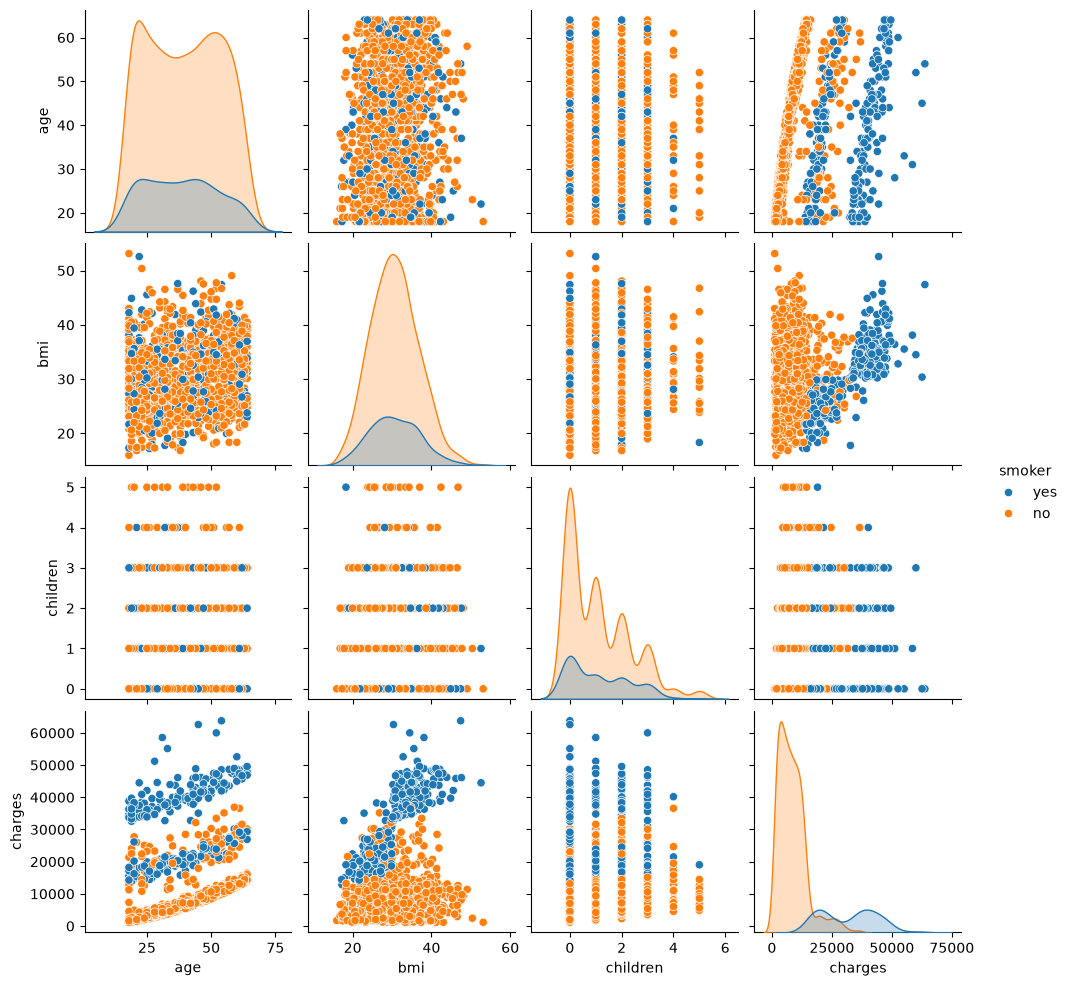

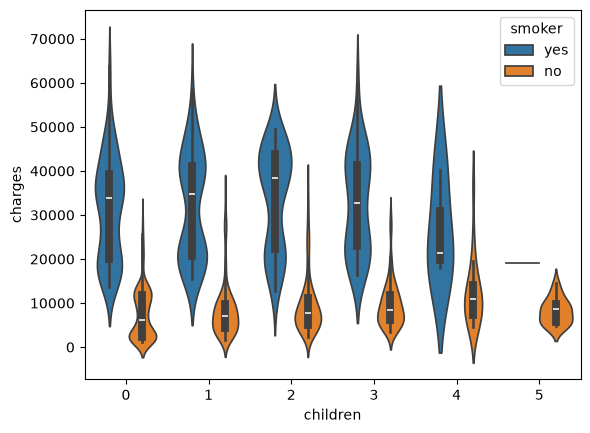

      age     sex   bmi  children smoker   charges
1085   39  female  18.3         5    yes  19023.26


In [75]:
# Code for your answer here!
# (a)
df_insurance.info()
df_insurance.describe()
df_insurance.isnull().sum()

# (b) 
sns.pairplot(df_insurance, hue="smoker", diag_kind="auto")
plt.show()

sns.violinplot(x="children", y="charges", data=df_insurance, hue="smoker")
plt.show()

filtered_df = df_insurance[(df_insurance['children'] == 5) & (df_insurance['smoker'] == 'yes')]
print(filtered_df)



_Type your ansher here_

(a) Here we see that we have two integer types, being age and children. Followed by two float types, bmi and charges. Finally, we have two string types which are sex and smoker. There arent any missing values as there ae 1338 rows, and each column has 1338 entries.

(b) Investigating how ages efects these differnet patterns, we see that with regards to bmi it is pretty random, maybe with a slight upwards trend. We see no direct correlation with smoking in this graph. Now looking at age with charges, theres an obvous upwards trend, whcih makes sense. Ontop of that the smokers tend to have higher charges which also makes sense as their generally less healthy. The same is with bmi and charges, the higher the bmi the more lightly to have higher charges, with smokers once again perfomring the worst. To investiage the effect of children we need a violin plot. This indicates to us a stark differnece between the spread of people with kids who smoke and those that don't, and how much more they get charged. With non smokers gettting charges substantially less no mattet the number of children. Interestingly for smokers with 5 children we only have one data point, meaning we would need more data in this case to make any claims regarding this. 

## Creating a Train-Test Set <a id='gen'></a>

Before modelling, we will first split the data into the train and test sets. This ensures that that we do not violate one of the golden rules of machine learning: never use the test set for training. As EDA can help guide the choice and form of model, we ideally want to split the data before EDA, to avoid peeking at the test data too much during this phase. However, in practice, we may need to investigate the entire data during EDA to get a better idea on how to handle issues such as missingness, categorical data (and rare categories), incorrect data, etc.      

There are lots of ways of creating a test set. We will use a helpful function from `sklearn.model_selection` called `train_test_split`. You can have a look at the documentation: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html. Note that `train_test_split` defaults to randomly sampling the data to split it into training and validation/test sets, that is, the default value is `shuffle=True`  

For reproducibility, we first fix the value in the numpy random seed about the state of randomness. This ensures that, every step including randomness, will produce the same output if we re-run the code or if someone else wants to reproduce our results (e.g. produce the same train-test split).

In `sklearn`, the suggestion to control randomness across multiple consecutive executions is as follows: 

- In order to obtain reproducible (i.e. constant) results across multiple program executions, we need to remove all uses of `random_state=None`, which is the default.

- Declare your own `rng` variable (random number generator) at the top of the program, and pass it down to any object that accepts a `random_state` parameter. You can check some details from here; https://numpy.org/doc/1.16/reference/generated/numpy.random.RandomState.html

Thus, our first step before splitting the data is to define our `rng` variable.

In [76]:
# To make this notebook's output identical at every run
rng = np.random.seed(0)
# might be good for our course
# np.random.seed(11205) 

### 🚩 Exercise 2 (CORE)

Run the following code to use `train_test_split()` to split the data randomly into training (70%) and test (30%) sets. The `training set` will contain our training data, called `X_train` and `y_train`. The `test set` will contain our testing data, called `X_test` and `y_test`.

Can you think on a scenario where not shuffling would be a good idea? What about when we do want to shuffle our data?

In [77]:
# As a good practice first split the data
from sklearn.model_selection import train_test_split

X = df_insurance.drop('charges', axis = 1) # Set of features
y = df_insurance['charges']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = rng)

print(X.shape)

(1338, 5)


_Type your answer here_

I think possible reasons shuffling wouldn't be a good idea is if there is a speciifc order of the data. Lets ssay for example the rows go in chronological order, thus huffling would mess up the timeline of this data.

# Least Squares Estimation <a id='RBH'></a>

Consider a linear regression model for `charges` using `bmi` and `smoker` as features in our model. Without sklearn functionalities, let's compute and visualise the least squares estimates.

### 🚩 Exercise 3 (CORE)

Create a scatter plot using `sns.scatterplot` of `charges` vs `bmi`, colored by `smoker`. Describe any apparent relationship between `charges` and `bmi` and comment on the difference between smokers and non-smokers.

<Axes: xlabel='bmi', ylabel='charges'>

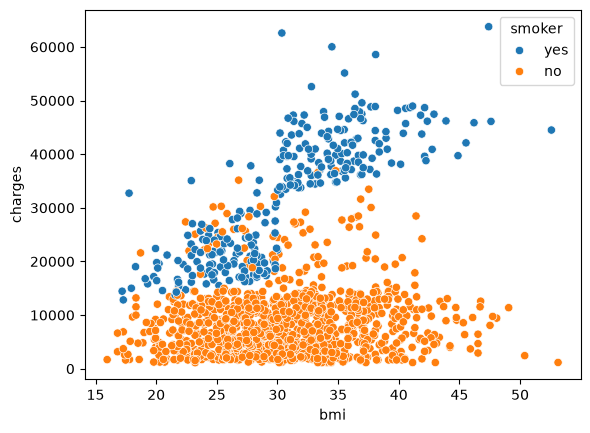

In [78]:
# Code for your answer here!

sns.scatterplot(x='bmi', y = 'charges', hue= 'smoker', data=df_insurance)

_Type your answer here_

There is a clear correlation between bmi and charges, as already mentioned. The higher the bmi, the higher the health charges which makes sense as people are less healthy. Ontop of that, if someone is a smoker then they're drastically more lightly to have higher bmi aswell as higher charges, represeented in the blue. There is a strange jump at around 30 bmi, for smoker. With an almost 10k increase in charges. This could be due to biological factors, which kick in severely at a bmi of around 30.

### 🚩 Exercise 4 (CORE)

Now, let's compute the least square estimates.

First let's construct the feature matrix as an `np.array`. Recall that we need to include a column of ones to allow a non-zero intercept. We also need to convert the response `y_train` to an `np.array`.

In [79]:
# Writing the design matrix
X = np.c_[
    np.ones(len(X_train)),
    X_train.bmi,
    X_train.smoker == "yes"
]

# Converting response training object to numpy array
y = np.array(y_train)

X.shape, y.shape

((936, 3), (936,))


a) Next, compute the least squares estimates $\hat{\boldsymbol{w}}$, using the expression from lectures and the `solve` function from `numpy.linalg`.

b) What is the intercept for non-smokers and what is the intercept for smokers?

In [80]:
# Code for your answer here!

#(a) from lecture we have ols is 

ols_m = np.linalg.solve(X.T @ X, X.T @ y)
print(f"w_hat = {ols_m}")



w_hat = [-3385.172326     389.05002587 22926.48168453]


(b) For smoker, we see that the ols estimate would gives us a intercept of w_0 + w_2*1 = -3385.172326 + 22926.48168453 = 19541.31, as X_train.smoker == "yes" gives 1. Therefore, for non-smokers, the intercept is simply -3385.17.

### 🚩 Exercise 5 (CORE)

a) Compute the fitted values from this model by calculating $\hat{\mathbf{y}} = \boldsymbol{X} \hat{\boldsymbol{w}}$. 

b) Redraw your scatter plot of `charges`vs `bmi`, colored by `smoker` from Exercise 3, and overlay a line plot of the fitted values (fitted regression line) using `sns.lineplot`. Comment on the results and any potential feature engineering steps that could help to improve the model.  

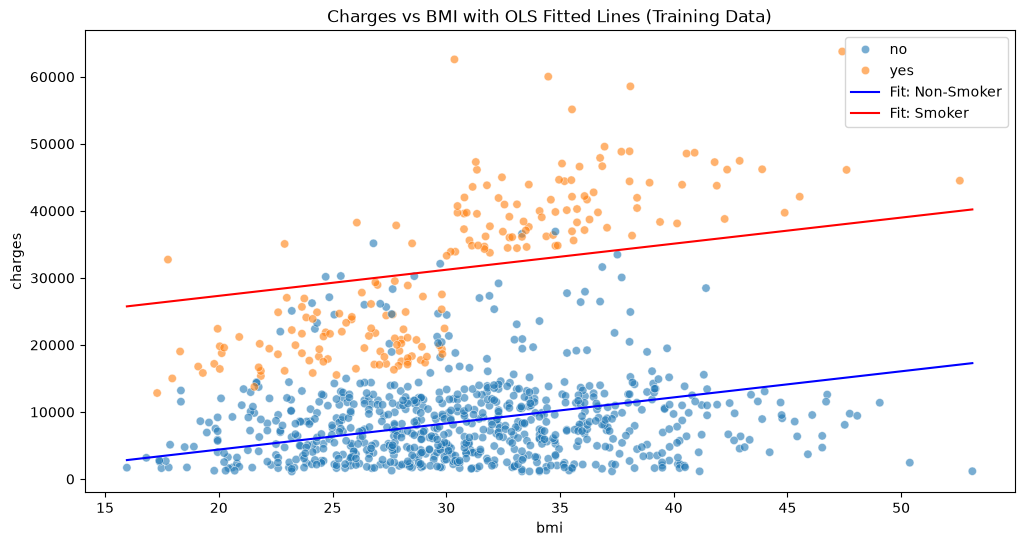

In [81]:
### Code for your answer here

y_hat = X @ ols_m

df_plot = X_train.copy()
df_plot['charges'] = y_train
df_plot['y_hat'] = y_hat

bmi_range = np.linspace(df_plot['bmi'].min(), df_plot['bmi'].max(), 100)

grid_no = pd.DataFrame({
    'bmi': bmi_range,
    'smoker': False 
})
# Create grid for Smokers (True/1)
grid_yes = pd.DataFrame({
    'bmi': bmi_range,
    'smoker': True 
})

X_grid_no = np.c_[np.ones(len(grid_no)), grid_no['bmi'], grid_no['smoker']]
X_grid_yes = np.c_[np.ones(len(grid_yes)), grid_yes['bmi'], grid_yes['smoker']]

grid_no['y_hat'] = X_grid_no @ ols_m
grid_yes['y_hat'] = X_grid_yes @ ols_m


fig, ax = plt.subplots(figsize=(12, 6))

sns.scatterplot(x='bmi', y='charges', hue='smoker', data=df_plot, ax=ax, alpha=0.6)

sns.lineplot(x='bmi', y='y_hat', data=grid_no, ax=ax, color='blue', label='Fit: Non-Smoker')
sns.lineplot(x='bmi', y='y_hat', data=grid_yes, ax=ax, color='red', label='Fit: Smoker')

ax.set_title('Charges vs BMI with OLS Fitted Lines (Training Data)')
plt.show()


_Type your answer here_

In this plot, we see that our interpretation of the scatterplot initially was correct. Both smokers and non-smokers, charges' rise as their bmi increases. This makes sense as a higher bmi means you're more unhealthy majority of the time. What is significant is how the two fitted lines are parallel, with seemingly constant differnece of 20k between smokers, and non-smokers hospital charges.

What is interesting though is that the regressions line for smokers, seems incorrect. As there is a sharper rise in bmi for smokers than the line suggets. Looks as though is could be a quadratic estimate function.

### 🚩 Exercise 6 (EXTRA)

In the following code following code, we compute the standard error for the predictions following the expression in lectures. Add dashed lines to your plot representing the prediction intervals for smokers and non-smokers.

In [82]:
# Compute standard error of predictions
sigmsq = np.sum((y - y_hat)**2) / (X.shape[0] - X.shape[1]-1)
sd_err_pred  = np.array([np.sqrt(sigmsq * X[i,:] @ np.linalg.solve(X.T@X, X[i,:].T)) for i in range(X.shape[0])])
#print(X)

In [83]:
# Code for your answer here!


## Residuals

A useful tool for evaluating a model is to examine the residuals of that model. For any standard regression model,  the residual for observation $n$ is defined as $y_n - \hat{y}_n$ where $\hat{y}_n$ is the model's fiited value for observation $n$. 

Studying the properties of the residuals is important for assessing the quality of the fitted regression model. This scatterplot (fitted vs residuals) gives us more intuition about the model performance. Briefly, 

>- If the normal linear model assumption is true then the residuals should be randomly scattered around zero with no discernible clustering or pattern with respect to the fitted values. 
>- Furthermore, this plot can be useful to check the constant variance (homoscedastic) assumption to see whether the range of the scatter of points is consistent over the range of fitted values.

### 🚩 Exercise 7 (CORE)

a) Calculate the residuals and create a residual plot (scatter plot of fitted vs residuals) for this model and color by smoker. Comment on quality of the model based on this plot.

b) Compute the $R^2$ value for this model and comment on its value (recall from lectures that $R^2$ is 1 minus the sum of the squared residuals divided by the sum of squared differences between $\mathbf{y}$ and its mean).

Shape of y: (936,), shape of y_hat: (936,)
(1338, 6)
(936, 3)


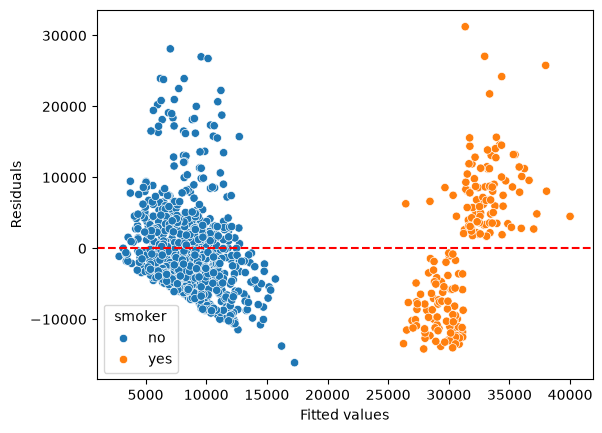

In [84]:
# Part a: Code for your answer here!

print(f"Shape of y: {y.shape}, shape of y_hat: {y_hat.shape}")

print(df_insurance.shape)
print(X.shape)

residual = y - y_hat
residual.shape

df_plot['residual'] = residual

sns.scatterplot(data=df_plot, x='y_hat', y='residual', hue='smoker')
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Fitted values')
plt.ylabel('Residuals')
plt.show()

_Part a: Type your answer here_

Here we see that this plot distinctly seperates the smokers from the non-smokers. We see that the non-smokers have lower fitted values, expected from our analysis as their more healthy. COmpared to the smokers with higher as expected too. 

Now looking at residuals we see see that the majority of the non-smokers are centered around 0, with some right skew. Now looking at the smokers, a small number of fitted values actually have low residuals. With the ajority skewed to the left. We could expect this as our model only takes into account if people smoke with a linear relationship. 

In [85]:
# Part b: Code for your answer here!


R_sqd = 1 - (sum(residual**2)/sum(y - np.mean(y))**2)
print(R_sqd)

-1.0516811154965885e+29


_Part b: Type your answer here_

As expected the R squared value for the model is very low (-8). This shows how badly the model predicts. This is expected, as our residuals values were large, especially for the smokers.

---
# Regression using scikit-Learn <a id='RSKL'></a>

Linear regression is available in **scikit-learn** (**sklearn**) through `LinearRegression` from the `linear_model` submodule. You can browse through the documentation and examples [here](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html). Let's start by importing it.

In [86]:
from sklearn.linear_model import LinearRegression

In general sklearn's models are implemented by first creating a model object, and then using that object to fit your data. As such, we will now create a linear regression model object `lr` and use it to fit our data. Once this object is created we use the `fit` method to obtain a model object fitted to our data. 

_Note:_ by default an intercept is included in the model. So, we do NOT need to add a column of ones to our design matrix.

_Note:_ in the code below we use `make_column_transformer` which automatically names all of our transformers. To see the names, run `preprocessor.named_transformers_`. You can then access each transformer by its name, if you want to view it's attributes or call methods on it, e.g. `preprocessor['onehotencoder'].get_feature_names_out()`.

_Note:_ using the option `OneHotEncoder(drop=np.array(['Reference Category']))`, we can specify the which category to drop (the reference category) by replacing `'Reference Category'` with the desired category.

In [87]:
lr = LinearRegression()

# Create feature matrix
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler

preprocessor = make_column_transformer(
    (OneHotEncoder(drop=np.array(['no'])), ['smoker']), # encode 'smoker' column
    (StandardScaler(), ['bmi']), # scale 'bmi' column
    remainder='drop', # drop everthing else
    verbose_feature_names_out=False)
X_train_ = preprocessor.fit_transform(X_train)

lr_fit = lr.fit(
    X = X_train_, 
    y = y_train
)

print(X_train.shape)

# To see the names of the transformers
# preprocessor.named_transformers_
# You can call a method or access attributes of each transformer by its name
# preprocessor['onehotencoder'].get_feature_names_out()

(936, 5)


This model object then has various useful methods and attributes, including `intercept_` and `coef_` which contain our estimates for $\boldsymbol{w}$. 

_Note:_ if `fit_intercept=False` and a column of ones is included in the design matrix, then both the intercept and coefficient will be stored in `coef_`.

In [88]:
w_0 = lr_fit.intercept_  # Intercept term of the fitted model
w_1 = lr_fit.coef_ 

w = np.concatenate([[w_0], w_1])
feature_names = ['intercept'] + list(preprocessor.get_feature_names_out())  
w_df = pd.DataFrame({'feature': feature_names, 'coefficient': w})
w_df

,feature,coefficient
0,intercept,8579.036638
1,smoker_yes,22926.481685
2,bmi,2424.659184


Importantly, to avoid _data leakage_ and improve _reproducibility_, we should always be combining our feature enginnering and model fitting steps into a single **pipeline**. 

_Note:_ in the code below we use `make_pipeline` which automatically names all of our transformers/estimators. To see the names, run `preprocessor.named_steps`. You can then access each step by its name or its index in the pipeline, e.g. `pipe['columntransformer'].get_feature_names_out()`.

In [89]:
# Combine into pipeline

from sklearn.pipeline import make_pipeline
pipe = make_pipeline(
    preprocessor,
    LinearRegression()
)

pipe_fit = pipe.fit(
    X = X_train,
    y = y_train
)

# You can access the coefficients by the index of the final step
pipe[-1].coef_ 
# Or by its name
# pipe.named_steps
# pipe['linearregression'].coef_

array([22926.48168453,  2424.65918409])

The model fit objects also provides additional useful methods for evaluating the model $R^2$ (`score`) and calculating predictions (`predict`). Let's use the latter to compute the fitted values and predictions, as well as some metrics to evaluate the performance on the test data.

In [90]:
# Fitted values
y_fit = pipe.predict(X_train)

# Predicted values
y_pred = pipe.predict(X_test)

# The mean squared error of the training set 
print("Training Mean squared error: %.3f" % mean_squared_error(y_train, y_fit))
# The R squared of the training set 
print("Training R squared: %.3f" % r2_score(y_train, y_fit))

# The mean squared error of the test set 
print("Test Mean squared error: %.3f" % mean_squared_error(y_test, y_pred))
# The R squared of the test set 
print("Test R squared: %.3f" % r2_score(y_test, y_pred))

# Another way for R2 calculation
print(pipe.score(X_train, y_train)) 

Training Mean squared error: 51446335.408
Training R squared: 0.635
Test Mean squared error: 47297000.691
Test R squared: 0.703
0.6350967450118401


Or we can use our helper function and also plot the fitted values and residuals to identify if there are potential patterns.

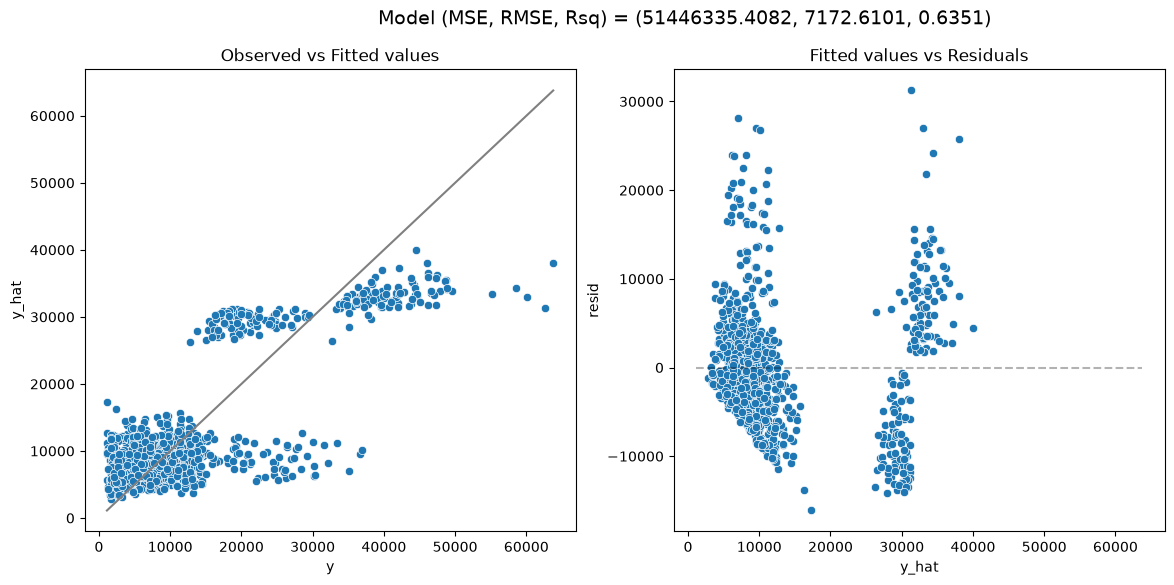

(51446335.408195145, 7172.610083379352, 0.6350967450118401)

In [91]:
# If we use the pre-defined function
model_fit(pipe, X_train, y_train, plot = True)

Lastly, we can use our helper function to compute standard errors of the coefficients and plot them.

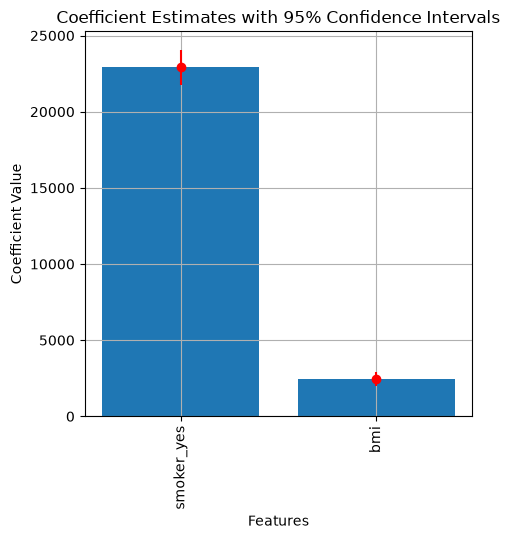

In [92]:
sd, cov_mat = compute_std_error(pipe, X_train, y_train, plot=True, feature_names=['smoker_yes', 'bmi'])

### 🚩 Exercise 8 (CORE)

Next, modify your pipeline to also include `age` as feature.

Fit the model on the training data and calculate performance metrics similar to above ($R^2$, and MSE / RMSE). How does this model compare to previous one?

{'onehotencoder': OneHotEncoder(drop=array(['no'], dtype='<U2')), 'standardscaler-1': StandardScaler(), 'standardscaler-2': StandardScaler(), 'remainder': 'drop'}
Training Mean squared error: 38378125.032
Training R squared: 0.728
Test Mean squared error: 33920514.905
Test R squared: 0.787
0.6350967450118401


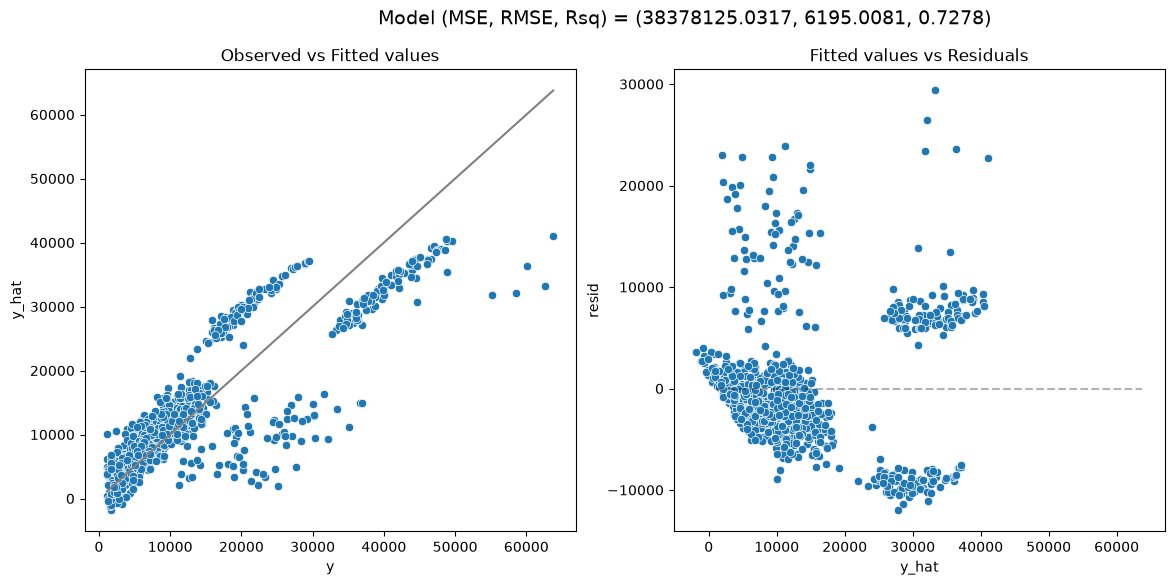

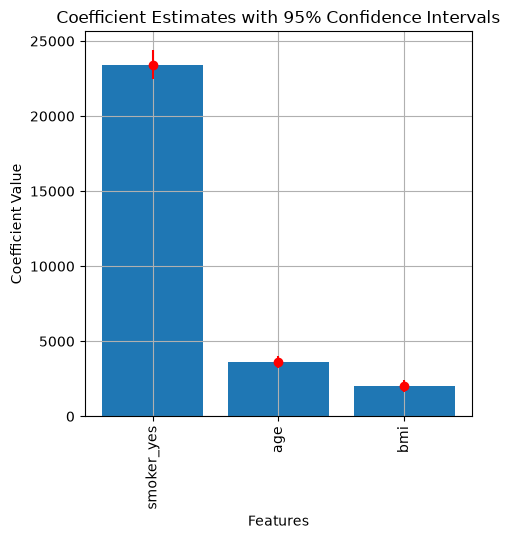

In [93]:
# Code for your answer here!

lr = LinearRegression()

# Create feature matrix
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler

preprocessor = make_column_transformer(
    (OneHotEncoder(drop=np.array(['no'])), ['smoker']), # encode 'smoker' column
    (StandardScaler(), ['bmi']), # scale 'bmi' column
    (StandardScaler(), ['age']),
    remainder='drop', # drop everthing else
    verbose_feature_names_out=False)
X_train_ = preprocessor.fit_transform(X_train)

lr_fit = lr.fit(
    X = X_train_, 
    y = y_train
)

# To see the names of the transformers
# preprocessor.named_transformers_
# You can call a method or access attributes of each transformer by its name
# preprocessor['onehotencoder'].get_feature_names_out()

print(preprocessor.named_transformers_)

w_0_age = lr_fit.intercept_  # Intercept term of the fitted model
w_1_age = lr_fit.coef_ 

w_age = np.concatenate([[w_0_age], w_1_age])
feature_names = ['intercept'] + list(preprocessor.get_feature_names_out())  
w_df_age = pd.DataFrame({'feature': feature_names, 'coefficient': w_age})
w_df_age

# Combine into pipeline

from sklearn.pipeline import make_pipeline

pipe_age = make_pipeline(
    preprocessor,
    LinearRegression()
)

pipe_fit_age = pipe_age.fit(
    X = X_train,
    y = y_train
)

# You can access the coefficients by the index of the final step
# Or by its name
# pipe.named_steps
# pipe['linearregression'].coef_

# Fitted values
y_fit_age = pipe_age.predict(X_train)

# Predicted values
y_pred_age = pipe_age.predict(X_test)

# The mean squared error of the training set 
print("Training Mean squared error: %.3f" % mean_squared_error(y_train, y_fit_age))
# The R squared of the training set 
print("Training R squared: %.3f" % r2_score(y_train, y_fit_age))

# The mean squared error of the test set 
print("Test Mean squared error: %.3f" % mean_squared_error(y_test, y_pred_age))
# The R squared of the test set 
print("Test R squared: %.3f" % r2_score(y_test, y_pred_age))

# Another way for R2 calculation
print(pipe.score(X_train, y_train)) 

# If we use the pre-defined function
model_fit(pipe_age, X_train, y_train, plot = True)

sd_age, cov_mat_age = compute_std_error(pipe_age, X_train, y_train, plot=True, feature_names=['smoker_yes', 'bmi', 'age'])

_Type your answer here_

This model better fits the data and predicts it. We know this as it has a higher R squared value of 0.74, compared to 0.65 of the previous model that didn't include age. The closer to 1 the R squared value the better the fit of the model, thus our new model is substantialy better than the previous model. In the graoh we see the still clear diffrences between smokers and non-smokers. But the general trend of the residuals are much closer to zero. 

--------

# Polynomial Regression<a id='polyreg'></a>


## Polynomial features in sklearn

sklearn has a built in function called `PolynomialFeatures` which can be used to simplify the process of including polynomial features in a model. You can browse the documentation [here](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html). This function is included in the *preprocessing* module of sklearn, as with other python functions we can import it as follows.

In [94]:
from sklearn.preprocessing import PolynomialFeatures

Construction and use of this is similar to what we have already seen with other transformers; we construct a PolynomialFeatures object in which we set basic options (e.g. the degree of the polynomial) and then apply the transformation to our data by calling `fit_transform`. This will generate a new model matrix which includes the polynomial features up to the degree we have specified.

Run the following code for a simple illustration:

In [95]:
x = np.array([1, 2, 3, 4])
PolynomialFeatures(degree = 2).fit_transform(x.reshape(-1,1))


array([[ 1.,  1.,  1.],
       [ 1.,  2.,  4.],
       [ 1.,  3.,  9.],
       [ 1.,  4., 16.]])

Note that when we use this transformation, we get **all of the polynomial transformations of x from 0 to degree**. 

In this case, the **0 degree column** is equivalent to **the intercept column**. If we do not want to include this we can construct `PolynomialFeatures` with the option `include_bias=False`.

In [96]:
PolynomialFeatures(degree = 2, include_bias=False).fit_transform(x.reshape(-1,1))

array([[ 1.,  1.],
       [ 2.,  4.],
       [ 3.,  9.],
       [ 4., 16.]])

We can also use `PolynomialFeatures` to add only interaction terms, through the option `interaction_only=True`. As an illustration run the following code:

In [97]:
x = np.array([[1, 2, 3, 4],[0,0,1,1]]).T
PolynomialFeatures(interaction_only=True,include_bias=False).fit_transform(x)

array([[1., 0., 0.],
       [2., 0., 0.],
       [3., 1., 3.],
       [4., 1., 4.]])

## Interactions

Now, let's create a pipeline that:

- includes `bmi` as a numerical variable and smoker condition as a categorical variable

- applies encoding for the `smoker` variable

- uses `PolynomialFeatures` to include an **interaction** between `smoker` and `bmi`

In [98]:
# Create Pipeline for model that includes interactions
preprocessor = make_column_transformer(
    (OneHotEncoder(drop=np.array(['no'])), ['smoker']), # encode 'smoker' column
    (StandardScaler(), ['bmi']), # scale 'bmi' column
    verbose_feature_names_out=False)

# Create and fit new pipeline
pipe3 = make_pipeline(
    preprocessor,
    PolynomialFeatures(interaction_only=True,include_bias=False), # add extra step for interaction terms
    LinearRegression()
).fit(X_train, y_train)

_Note:_ we set `include_bias=False` as the intercept is included in linear regression by default.

We can also extract the **names of the features** using the method `get_feature_names_out()`. 

In [99]:
# Names after the first transformer
print(pipe3[0].get_feature_names_out())

# Names after the first transformer and interaction step
print(pipe3[:-1].get_feature_names_out())

# Create a data frame to see the intercept and coefficients
w = [pipe3[-1].intercept_] + pipe3[-1].coef_.tolist() 
feature_names = ['intercept'] + list(pipe3[:-1].get_feature_names_out())  
w_df = pd.DataFrame({'feature': feature_names, 'coefficient': w})
w_df

['smoker_yes' 'bmi']
['smoker_yes' 'bmi' 'smoker_yes bmi']


,feature,coefficient
0,intercept,8606.815570
1,smoker_yes,23291.340426
2,bmi,637.827154
3,smoker_yes bmi,8219.259903


### 🚩 Exercise 9 (CORE)

For the model trained above (`pipe3`):

a) What is the intercept and slope for non-smokers and what is the intercept and slope for smokers?

b) Compute the fitted values by calling `predict`. Draw the scatter plot of bmi against charges, colored by smoker (from Exercise 3), and overlay a line plot of the fitted values (fitted regression lines).

c) How does this model compare to our previous models `pipe` and `pipe2`?

['smoker_yes' 'bmi']
['smoker_yes' 'bmi' 'smoker_yes bmi']
      age     sex     bmi  children smoker
1163   18  female  28.215         0     no
196    39  female  32.800         0     no
438    52  female  46.750         5     no
183    44  female  26.410         0     no
1298   33    male  27.455         2     no
...   ...     ...     ...       ...    ...
763    27    male  26.030         0     no
835    42    male  35.970         2     no
1216   40    male  25.080         0     no
559    19    male  35.530         0     no
684    33  female  18.500         1     no

[936 rows x 5 columns]
this is (402, 5)


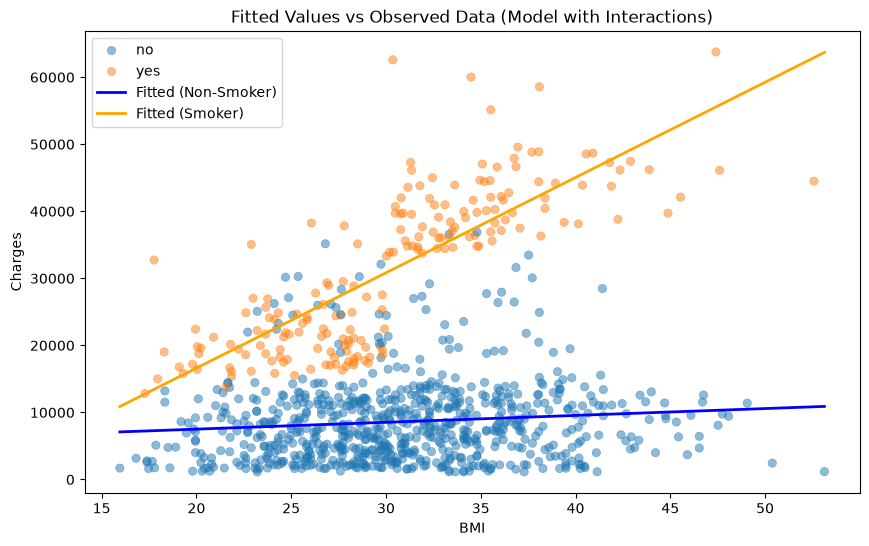

Training Mean squared error: 39963574.310
Training R squared: 0.717
Test Mean squared error: 33109843.739
Test R squared: 0.792
0.6350967450118401


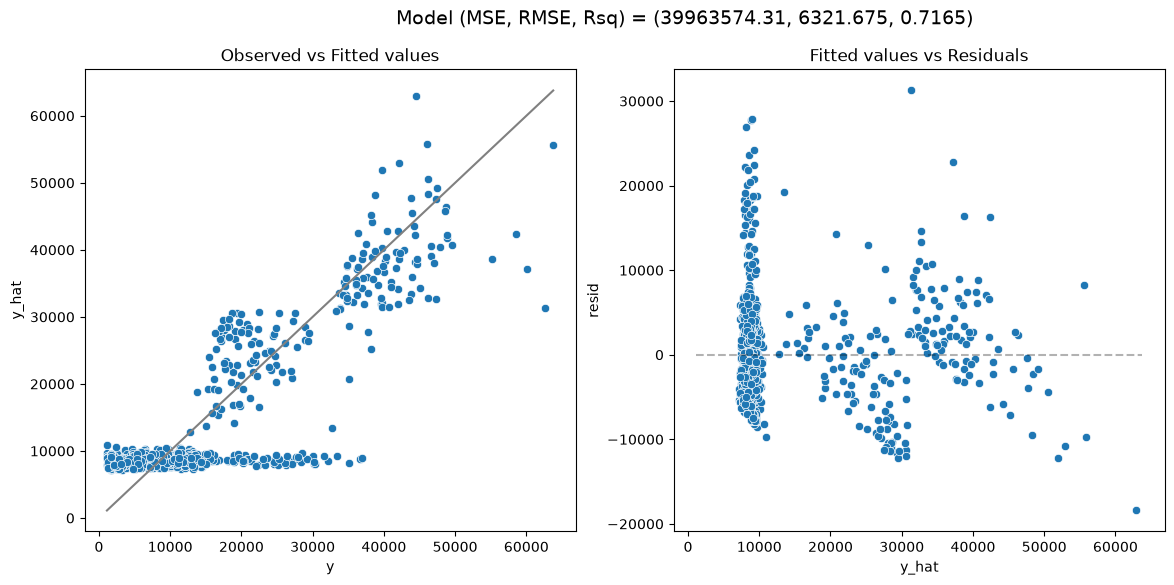

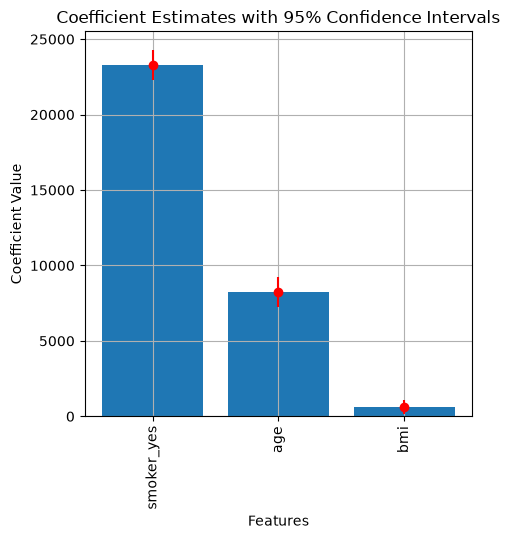

In [ ]:
# Code for your answer here 
#(a)

# Names after the first transformer
print(pipe3[0].get_feature_names_out())

# Names after the first transformer and interaction step
print(pipe3[:-1].get_feature_names_out())

# Create a data frame to see the intercept and coefficients
w = [pipe3[-1].intercept_] + pipe3[-1].coef_.tolist() 
feature_names = ['intercept'] + list(pipe3[:-1].get_feature_names_out())  
w_df = pd.DataFrame({'feature': feature_names, 'coefficient': w})
w_df


pipe_fit_3 = pipe3.fit(
    X = X_train, # column 2 is bmi and 3 is 
    y = y_train
)

#print(X_train)


# You can access the coefficients by the index of the final step
# Or by its name
# pipe.named_steps
# pipe['linearregression'].coef_

# Fitted values
y_fit_3 = pipe_fit_3.predict(X_train)

# Predicted values
y_pred_3 = pipe_fit_3.predict(X_test)

#print(f'this is {X_test.shape}')


plt.figure(figsize=(10, 6))
sns.scatterplot(x=X_train['bmi'], y=y_train, hue=X_train['smoker'], 
                alpha=0.5, edgecolor=None)


bmi_min = X_train['bmi'].min()
bmi_max = X_train['bmi'].max()
bmi_range = np.linspace(bmi_min, bmi_max, 100)

# Create DataFrames 
grid_no = pd.DataFrame({'bmi': bmi_range, 'smoker': 'no'})
grid_yes = pd.DataFrame({'bmi': bmi_range, 'smoker': 'yes'})

#use the fitted pipeline

pred_no = pipe3.predict(grid_no)
pred_yes = pipe3.predict(grid_yes)

#Overlay the regression lines
plt.plot(bmi_range, pred_no, color='blue', linewidth=2, label='Fitted (Non-Smoker)')
plt.plot(bmi_range, pred_yes, color='orange', linewidth=2, label='Fitted (Smoker)')

plt.xlabel('BMI')
plt.ylabel('Charges')
plt.title('Fitted Values vs Observed Data (Model with Interactions)')
plt.legend()
plt.show()


# The mean squared error of the training set 
print("Training Mean squared error: %.3f" % mean_squared_error(y_train, y_fit_3))
# The R squared of the training set 
print("Training R squared: %.3f" % r2_score(y_train, y_fit_3))

# The mean squared error of the test set 
print("Test Mean squared error: %.3f" % mean_squared_error(y_test, y_pred_3))
# The R squared of the test set 
print("Test R squared: %.3f" % r2_score(y_test, y_pred_3))

# Another way for R2 calculation
print(pipe.score(X_train, y_train)) 

# If we use the pre-defined function
model_fit(pipe3, X_train, y_train, plot = True)

sd_age, cov_mat_age = compute_std_error(pipe3, X_train, y_train, plot=True, feature_names=['smoker_yes', 'bmi', 'age'])



_Type your answer here_

(a) For smokers we the categorical varaible is equal to 1, thus have a intercept parameter of 8607+23291 = 31898, with a slope coefficient of 638 + 8219= 8857. Compared to the non-smokers with a a smoker_yes = 0, thus the intercept term is, 8607. And the slope coefficient is 638.

(b) code block above

(c) This final model (pipe3) is much better than the first, and second model, with regression lines clearly showing the fit is much more significant. As well as that, the Test R squared value for pipe3 is 0.792 compared to model 2's of 0.787 and model 1's of 0.703. Looking at training R squared we see a slightly different story however. The Test R squared value for pipe3 is 0.717, model 2's being 0.728, and 1's being 0.635. This indicates that the second model fits the data better. Therefore the previous assessment could be biased on the fact that the there is less Test data, thus more variance in fitting it?

We see a regression line that seems to fit the data very well for pipe3.

## Nonlinearity

Now, let's explore including nonlinearity into the model through a polynomial basis function expansions of `bmi`.

### 🚩 Exercise 10 (CORE)

First, suppose you naively apply a polynomial basis function expansion to the feature matrix containing `bmi` and `smoker`: 

- Run the code below to create the transformed feature matrix using `PolynomialFeatures` assuming `degree=2`. 

- Why should we **NOT** use this naive polynomial basis function expansion?

In [110]:
# Create a transformed feature matrix containing a polynomial expansion (degree 2) of bmi and smoker 

# Create Pipeline for model that includes interactions
preprocessor = make_column_transformer(
    (OneHotEncoder(drop=np.array(['no'])), ['smoker']), # encode 'smoker' column
    (StandardScaler(), ['bmi']), # pass through 'bmi' column
    verbose_feature_names_out=False)

# Create and fit new pipeline
fe = make_pipeline(
    preprocessor,
    PolynomialFeatures(degree=2), # add step for polynomial features
)

Xt = fe.fit_transform(X_train)
Xt_ = pd.DataFrame(Xt, columns=fe.get_feature_names_out())
Xt_.head()

,1,smoker_yes,bmi,smoker_yes^2,smoker_yes bmi,bmi^2
0,1.0,0.0,-0.407135,0.0,-0.0,0.165759
1,1.0,0.0,0.328554,0.0,0.0,0.107948
2,1.0,0.0,2.566909,0.0,0.0,6.589022
3,1.0,0.0,-0.696757,0.0,-0.0,0.485470
4,1.0,0.0,-0.529081,0.0,-0.0,0.279926


_Type your answer here_

The addition of a degree two polynomial could be considered naieve, as the trend may be linear. For example the charges for non-smokers, appears to be linear, whereas the smokers, we do not know. As well as this, it could overfit the model using a degree two polynomial.


### 🚩 Exercise 11 (CORE)

Now, let's create a model that allows nonlinearity of `bmi` through polynomial basis function expansion of degree 3 (with no interactions for ease of exposition). 

Create a new pipeline to construct this model. Train this model and then plot the fitted regression line and compute the performance metrics.

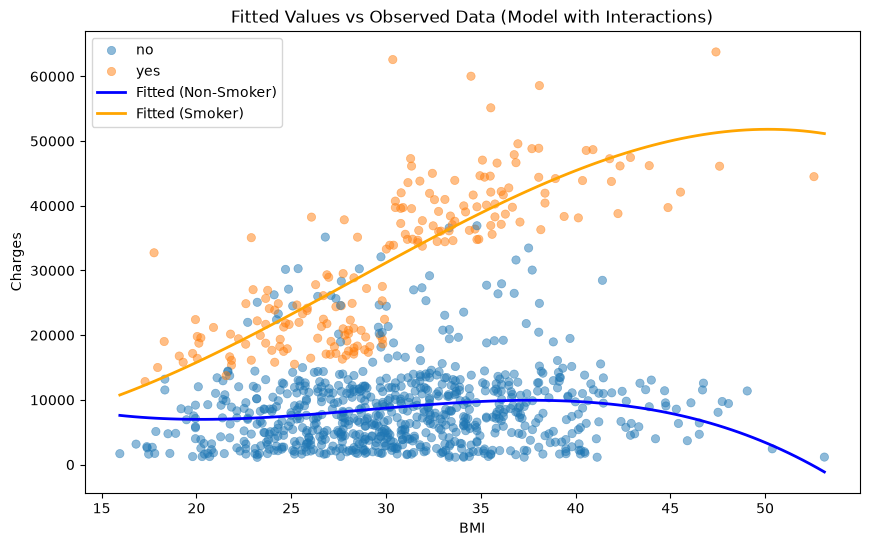

Training Mean squared error: 39086700.730
Training R squared: 0.723
Test Mean squared error: 32613826.173
Test R squared: 0.795
0.6350967450118401


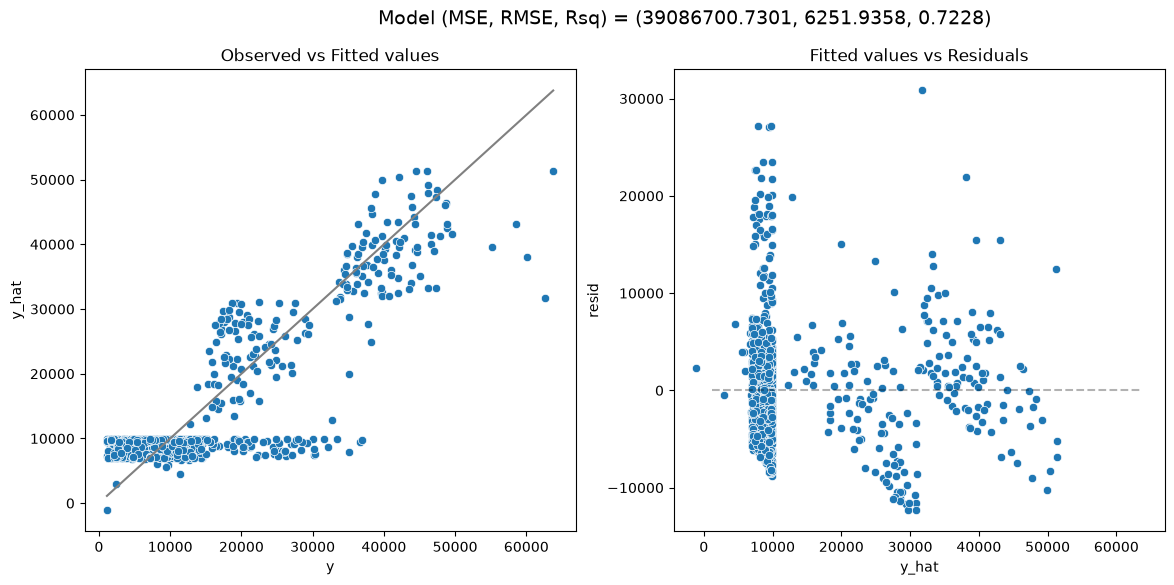

LinAlgError: Singular matrix

In [116]:
# Code for your answer here

# Create Pipeline for model that includes interactions
preprocessor = make_column_transformer(
    (OneHotEncoder(drop=np.array(['no'])), ['smoker']), # encode 'smoker' column
    (StandardScaler(), ['bmi']), # scale 'bmi' column
    verbose_feature_names_out=False)

# Create and fit new pipeline
pipe4 = make_pipeline(
    preprocessor,
    PolynomialFeatures(degree=3,include_bias=False), # add extra step for interaction terms
    LinearRegression()
).fit(X_train, y_train)

pipe_fit_4 = pipe4.fit(
    X = X_train, # column 2 is bmi and 3 is smoker 
    y = y_train
)


# Fitted values
y_fit_4 = pipe_fit_4.predict(X_train)

# Predicted values
y_pred_4 = pipe_fit_4.predict(X_test)

#print(f'this is {X_test.shape}')


plt.figure(figsize=(10, 6))
sns.scatterplot(x=X_train['bmi'], y=y_train, hue=X_train['smoker'], 
                alpha=0.5, edgecolor=None)


bmi_min = X_train['bmi'].min()
bmi_max = X_train['bmi'].max()
bmi_range = np.linspace(bmi_min, bmi_max, 100)

# Create DataFrames 
grid_no = pd.DataFrame({'bmi': bmi_range, 'smoker': 'no'})
grid_yes = pd.DataFrame({'bmi': bmi_range, 'smoker': 'yes'})

#use the fitted pipeline

pred_no = pipe4.predict(grid_no)
pred_yes = pipe4.predict(grid_yes)

#Overlay the regression lines
plt.plot(bmi_range, pred_no, color='blue', linewidth=2, label='Fitted (Non-Smoker)')
plt.plot(bmi_range, pred_yes, color='orange', linewidth=2, label='Fitted (Smoker)')

plt.xlabel('BMI')
plt.ylabel('Charges')
plt.title('Fitted Values vs Observed Data (Model with Interactions)')
plt.legend()
plt.show()


# The mean squared error of the training set 
print("Training Mean squared error: %.3f" % mean_squared_error(y_train, y_fit_4))
# The R squared of the training set 
print("Training R squared: %.3f" % r2_score(y_train, y_fit_4))

# The mean squared error of the test set 
print("Test Mean squared error: %.3f" % mean_squared_error(y_test, y_pred_4))
# The R squared of the test set 
print("Test R squared: %.3f" % r2_score(y_test, y_pred_4))

# Another way for R2 calculation
print(pipe.score(X_train, y_train)) 

# If we use the pre-defined function
model_fit(pipe4, X_train, y_train, plot = True)

sd_age, cov_mat_age = compute_std_error(pipe4, X_train, y_train, plot=True, feature_names=['smoker_yes', 'bmi', 'age'])



## Choosing the Order of the Polynomial

How can we choose the order of the polynomial? 

In the lecture, we discussed how choosing the degree to be too large can cause over fittting. When we over fit a polynomial regression model, the MSE for the training data will appear to be low which might indicate that the model is a good fit. But, as a result of over fitting, the MSE for the predictions of the unseen test data may begin to increase. However, we can **NOT** use the test to determine the order of the polynomial, so in the following, we explore using cross-validation to do so.

### Tuning with GridSearchCV

If we wish to test over a specific set of parameter values using cross validation we can use the `GridSearchCV` function from the `model_selection` submodule. In this setting, the hyperparamer is actually the degree of the polynomial that we are investigating. 

This argument is a dictionary containing parameters names as keys and lists of parameter settings to try as values. Since we are using a pipeline, our parameter name will be the name of the pipeline step, `columntransformer`, followed by `__`, (then, the name of next step if applicable, e.g. `pipeline__` since we are using `Pipeline` for the steps of the numerical features, and `polynomialfeatures__` for the polynomial expansion) , and then the parameter name, `degree`. So for our pipeline the parameter is named `columntransformer__pipeline__polynomialfeatures__degree`. If you want to list the names of all available parameters you can call the `get_params()` method on the model object, e.g. `polyreg_pipe.get_params()` here.

In [ ]:
# Create Pipeline for model that includes polynomial expansions of bmi
num_pre = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(include_bias=False)
)

preprocessor = make_column_transformer(
    (OneHotEncoder(drop=np.array(['no'])), ['smoker']), # encode 'smoker' column
    (num_pre, ['bmi']), # polynomial features of 'bmi' column
    verbose_feature_names_out=False)

# Create the new pipeline
polyreg_pipe = make_pipeline(
    preprocessor,
    LinearRegression(), # add step for polynomial features
)

# To see the names of the parameters that can be tuned
# polyreg_pipe.get_params() #names of all parameters
# polyreg_pipe['columntransformer'].get_params()  #names of parameters for the preprocessor

In [ ]:
# Define parameter grid for degree of polynomial features
parameters = {
    'columntransformer__pipeline__polynomialfeatures__degree': np.arange(1,10,1)
}

# Define cross-validation scheme
kf = KFold(n_splits = 5, shuffle = True, random_state=rng)

# Grid search with cross-validation
grid_search = GridSearchCV(polyreg_pipe, parameters, cv = kf, 
                           scoring = 'neg_mean_squared_error', return_train_score=True).fit(X_train, y_train)

The above code goes through the process of fitting all $5 \times 9$ models as well as storing and ranking the results for the requested scoring metric(s). Note that here we have used `neg_mean_squared_error` as our scoring metric which returns the **negative of the mean squared error**. For more on metrics of regression models, please see: https://scikit-learn.org/stable/modules/model_evaluation.html#regression-metrics

- As the name implies this returns the negative of the usual fit metric, this is because sklearn expects to always optimize for the maximum of a score and the model with the largest negative MSE will therefore be the "best". 

- In this workshop we have used MSE as a metric for testing our models. This metric is entirely equivalent to the root mean squared error for purposes of ranking / ordering models (as the square root is a monotonic transformation). 
- Sometimes the RMSE is prefered as it is more interpretable, because it has the same units as $y$.

Once all of the submodels are fit, we can determine the optimal hyperparameter value by accessing the object's `best_*` attributes,

In [ ]:
print("best index: ", grid_search.best_index_)
print("best param: ", grid_search.best_params_)
print("best score: ", grid_search.best_score_)

best index:  2
best param:  {'columntransformer__pipeline__polynomialfeatures__degree': np.int64(3)}
best score:  -51205617.18188195


The best estimator is stored in the `.best_estimator` attribute. By default, after this model is found, it is retrained on all training data points.

In [ ]:
grid_search.best_estimator_[-1].coef_

array([22996.56516622,  3008.02654513,  -395.36430999,  -147.96929141])

In [ ]:
# Extract the names of the features and coefficients
w = [grid_search.best_estimator_[-1].intercept_] + grid_search.best_estimator_[-1].coef_.tolist() 
feature_names = ['intercept'] + list(grid_search.best_estimator_[:-1].get_feature_names_out())  
w_df = pd.DataFrame({'feature': feature_names, 'coefficient': w})
w_df

,feature,coefficient
0,intercept,9010.405147
1,smoker_yes,22996.565166
2,bmi,3008.026545
3,bmi^2,-395.364310
4,bmi^3,-147.969291


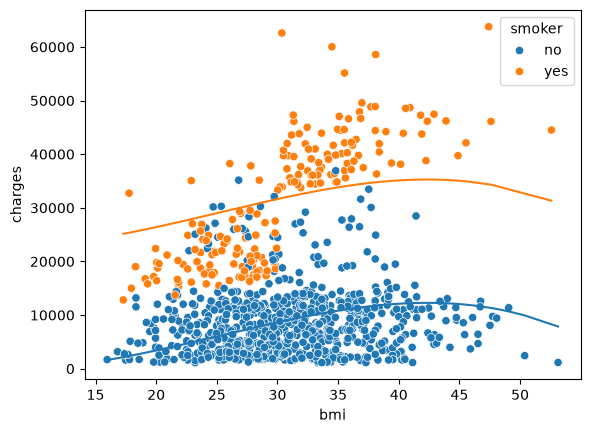

In [ ]:
# Compute fitted values
yhat =grid_search.predict(X_train)

# Plot fitted values
ax = sns.scatterplot(x = X_train.bmi, y = y_train, hue = X_train.smoker)
sns.lineplot(x = X_train.bmi, y = yhat, hue = X_train.smoker, ax=ax, legend = False)
ax.set(ylabel='charges')
plt.show()

The cross-validated scores are stored in the attribute `cv_results_`. This contains a number of results related to the grid search and cross-validation. We can convert it into a pandas data frame to view the results.

In [ ]:
cv_results = pd.DataFrame(grid_search.cv_results_)
cv_results

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_columntransformer__pipeline__polynomialfeatures__degree,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,...,mean_test_score,std_test_score,rank_test_score,split0_train_score,split1_train_score,split2_train_score,split3_train_score,split4_train_score,mean_train_score,std_train_score
0,0.044423,0.042795,0.019138,0.001501,1,{'columntransformer__pipeline__polynomialfeatu...,-4.953120e+07,-5.421318e+07,-4.522664e+07,-5.802686e+07,...,-5.166557e+07,4.314726e+06,4,-5.197729e+07,-5.076974e+07,-5.300751e+07,-4.984967e+07,-5.150686e+07,-5.142221e+07,1.070237e+06
1,0.014951,0.006172,0.013246,0.005360,2,{'columntransformer__pipeline__polynomialfeatu...,-4.863959e+07,-5.332238e+07,-4.693936e+07,-5.682679e+07,...,-5.128167e+07,3.496021e+06,2,-5.150724e+07,-5.029181e+07,-5.197860e+07,-4.944856e+07,-5.095547e+07,-5.083633e+07,8.934741e+05
2,0.016877,0.003315,0.007217,0.003199,3,{'columntransformer__pipeline__polynomialfeatu...,-4.849697e+07,-5.323485e+07,-4.696317e+07,-5.677668e+07,...,-5.120562e+07,3.490302e+06,1,-5.141538e+07,-5.018797e+07,-5.185925e+07,-4.932849e+07,-5.086011e+07,-5.073024e+07,8.966502e+05
3,0.015416,0.002801,0.005370,0.004665,4,{'columntransformer__pipeline__polynomialfeatu...,-4.846416e+07,-5.318416e+07,-4.801395e+07,-5.687521e+07,...,-5.140654e+07,3.288286e+06,3,-5.139295e+07,-5.017128e+07,-5.166660e+07,-4.932628e+07,-5.085550e+07,-5.068252e+07,8.489775e+05
4,0.014049,0.001732,0.005281,0.001355,5,{'columntransformer__pipeline__polynomialfeatu...,-4.831336e+07,-5.309080e+07,-5.040526e+07,-5.682702e+07,...,-5.184219e+07,2.916572e+06,5,-5.138029e+07,-5.012581e+07,-5.131375e+07,-4.932590e+07,-5.077096e+07,-5.058334e+07,7.738649e+05
5,0.014619,0.001501,0.003803,0.004411,6,{'columntransformer__pipeline__polynomialfeatu...,-4.808782e+07,-5.313373e+07,-5.008987e+07,-5.815680e+07,...,-5.195127e+07,3.494678e+06,6,-5.124288e+07,-4.993415e+07,-5.130996e+07,-4.889950e+07,-5.065533e+07,-5.040837e+07,9.024238e+05
6,0.009297,0.003657,0.009889,0.001818,7,{'columntransformer__pipeline__polynomialfeatu...,-4.817562e+07,-5.326807e+07,-5.015651e+07,-5.828802e+07,...,-5.203563e+07,3.523907e+06,7,-5.106324e+07,-4.974739e+07,-5.130986e+07,-4.870798e+07,-5.050278e+07,-5.026625e+07,9.463269e+05
7,0.011931,0.005984,0.008274,0.004810,8,{'columntransformer__pipeline__polynomialfeatu...,-4.817024e+07,-5.308828e+07,-5.206927e+07,-5.876990e+07,...,-5.244722e+07,3.581987e+06,8,-5.097090e+07,-4.971758e+07,-5.114621e+07,-4.856394e+07,-5.045974e+07,-5.017167e+07,9.447169e+05
8,0.015484,0.001999,0.008558,0.001985,9,{'columntransformer__pipeline__polynomialfeatu...,-4.826592e+07,-5.320403e+07,-5.375387e+07,-5.884213e+07,...,-5.283836e+07,3.613367e+06,9,-5.094828e+07,-4.969361e+07,-5.109410e+07,-4.856170e+07,-5.045624e+07,-5.015078e+07,9.330973e+05


It is also recommend to plot the CV scores. Although the grid search may report a best value for the parameter corresponding to the maximum CV score (e.g. min CV MSE), if the curve is relatively flat around the minimum, we may prefer the simpler model.

Note in this case, I have also used the option `return_train_score=True` in `GridSearchCV()`, in order to save also the training scores. As expected training MSE decreases when increasing the degree of the polynomial, but the CV MSE has more of a U-shape.

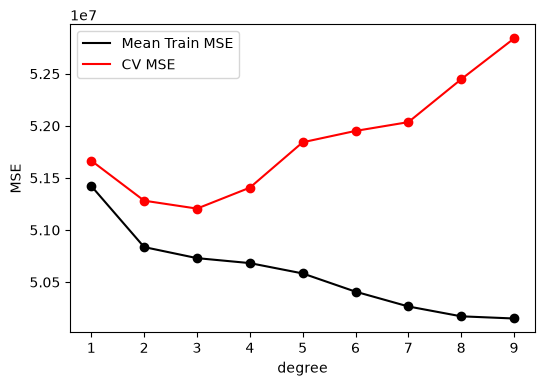

In [ ]:
degree = np.arange(1,10,1)
fig, ax = plt.subplots(1,1,figsize=(6,4))
plt.scatter(degree,-grid_search.cv_results_['mean_train_score'], color='k')
plt.plot(degree,-grid_search.cv_results_['mean_train_score'], color='k', label='Mean Train MSE')
plt.scatter(degree,-grid_search.cv_results_['mean_test_score'], color='r')
plt.plot(degree,-grid_search.cv_results_['mean_test_score'], color='r', label='CV MSE')
ax.legend()
ax.set_xlabel('degree')
ax.set_ylabel('MSE')
plt.show()

### 🚩 Exercise 12 (CORE)

Based on the plot above, would you use the best estimator or choose a different degree? Why?

Try changing `random_state` in the grid search to different value. Does the best estimator still choose the same degree?

_Type your answer here_

### 🚩 Exercise 13 (EXTRA)

Try an alternative model of your choice. What have you chosen and why? Are there any parameters to tune?

In [ ]:
# Code for your answer here


_Type your answere here_

### 🚩 Exercise 14 (CORE)

Have you used any form of generative AI when working on this assessment? If so, describe how you used which tool, and what you have learned from it.


_Type your answere here_

### Further resources

- About common pitfalls and interpreting coefficients: 

https://scikit-learn.org/stable/auto_examples/inspection/plot_linear_model_coefficient_interpretation.html#

# Completing the Worksheet

At this point you have hopefully been able to complete all the CORE exercises and attempted the EXTRA ones. Now 
is a good time to check the reproducibility of this document by restarting the notebook's
kernel and rerunning all cells in order.

Before generating the PDF, please **change 'Student 1' and 'Student 2' at the top of the notebook to include your name(s)**.

Once that is done and you are happy with everything, you can then run the following cell 
to generate your PDF. 

In [ ]:
!jupyter nbconvert --to pdf mlp_week04.ipynb 

usage: jupyter [-h] [--version] [--config-dir] [--data-dir] [--runtime-dir]
               [--paths] [--json] [--debug]
               [subcommand]

Jupyter: Interactive Computing

positional arguments:
  subcommand     the subcommand to launch

options:
  -h, --help     show this help message and exit
  --version      show the versions of core jupyter packages and exit
  --config-dir   show Jupyter config dir
  --data-dir     show Jupyter data dir
  --runtime-dir  show Jupyter runtime dir
  --paths        show all Jupyter paths. Add --json for machine-readable
                 format.
  --json         output paths as machine-readable json
  --debug        output debug information about paths

Available subcommands: kernel kernelspec migrate run troubleshoot

Jupyter command `jupyter-nbconvert` not found.
